# 04 - scikit-learn ile Makine Öğrenmesi
**Veri Madenciliği Dersi – Gümüşhane Üniversitesi, Yönetim Bilişim Sistemleri**

scikit-learn, Python'da klasik makine öğrenmesi için standart kütüphanedir. En büyük gücü, **tüm algoritmaların aynı arayüzü** kullanmasıdır: bir modeli öğrendiğinizde hepsini kullanmayı öğrenmiş olursunuz.

### Öğrenme Hedefleri
1. scikit-learn'ün ortak API'sini kavramak: `fit`, `predict`, `transform`
2. Veriyi **eğitim/test** olarak bölmek ve **veri sızıntısından (data leakage)** kaçınmak
3. Ön işleme: ölçeklendirme ve kategorik değişken kodlama
4. **Sınıflandırma** modelleri kurmak ve doğru metriklerle değerlendirmek
5. **Çapraz doğrulama**, `Pipeline` ve hiperparametre arama
6. **Regresyon** ve **kümeleme** (denetimsiz öğrenme) uygulamaları

### Veri Madenciliği Süreci (CRISP-DM'in modelleme kısmı)
`Veriyi hazırla → Böl → Ön işle → Modeli eğit → Değerlendir → İyileştir → Yorumla`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

plt.rcParams["figure.figsize"] = (7, 4.5)
print("scikit-learn sürümü:", sklearn.__version__)

scikit-learn sürümü: 1.8.0


## 1. Temel Kavramlar ve Ortak API ⭐
| Terim | Anlamı |
|---|---|
| `X` | Özellik (bağımsız değişken) matrisi – **2 boyutlu**: (gözlem sayısı, özellik sayısı) |
| `y` | Hedef (bağımlı değişken) – 1 boyutlu |
| **Denetimli öğrenme** | `y` biliniyor: sınıflandırma (kategorik `y`), regresyon (sayısal `y`) |
| **Denetimsiz öğrenme** | `y` yok: kümeleme, boyut indirgeme |

Her scikit-learn nesnesi aynı kalıbı izler:
```python
model = ModelSinifi(parametreler)   # 1. Oluştur
model.fit(X_egitim, y_egitim)       # 2. Eğit (öğren)
model.predict(X_yeni)               # 3. Tahmin et
model.score(X_test, y_test)         # 4. Değerlendir
```
Dönüştürücüler (ölçekleyici vb.) için: `fit` → `transform` (veya ikisi birden: `fit_transform`).

In [2]:
# En basit örnek: reklam harcamasından satışı tahmin etme
from sklearn.linear_model import LinearRegression

reklam = np.array([10, 20, 30, 40, 50]).reshape(-1, 1)   # X 2 boyutlu olmalı!
satis = np.array([55, 78, 98, 130, 148])

model = LinearRegression()
model.fit(reklam, satis)

print("Eğim (katsayı):", model.coef_.round(2))
print("Sabit terim    :", model.intercept_.round(2))
print("60 bin TL reklam için tahmin:", model.predict([[60]]).round(1))

Eğim (katsayı): [2.38]
Sabit terim    : 30.4
60 bin TL reklam için tahmin: [173.2]


## 2. Veri Seti: Telekom Müşteri Kaybı (Churn) Tahmini
Bir telekom şirketi, hangi müşterilerin aboneliğini iptal edeceğini (**churn**) önceden tahmin etmek istiyor. Böylece bu müşterilere özel kampanyalar sunabilir. Bu bir **ikili sınıflandırma** problemidir.

In [3]:
rng = np.random.default_rng(42)
n = 2000

df = pd.DataFrame({
    "yas": rng.integers(18, 70, n),
    "abonelik_ay": rng.integers(1, 72, n),
    "aylik_ucret": rng.uniform(150, 900, n).round(2),
    "destek_cagri": rng.poisson(1.5, n),
    "veri_kullanim_gb": rng.gamma(2.0, 8.0, n).round(1),
    "sozlesme": rng.choice(["Aylık", "1 Yıllık", "2 Yıllık"], n, p=[0.5, 0.3, 0.2]),
    "odeme": rng.choice(["Kredi Kartı", "Otomatik Ödeme", "Fatura"], n, p=[0.4, 0.35, 0.25]),
    "il_tipi": rng.choice(["Büyükşehir", "İl Merkezi", "İlçe"], n, p=[0.5, 0.3, 0.2]),
})

# Gerçekçi bir ilişki ile churn üretelim (logit modeli)
logit = (-2.6
         - 0.04 * df["abonelik_ay"]
         + 0.003 * df["aylik_ucret"]
         + 0.45 * df["destek_cagri"]
         - 0.015 * (df["yas"] - 40)
         + df["sozlesme"].map({"Aylık": 0.9, "1 Yıllık": -0.4, "2 Yıllık": -1.3})
         + df["odeme"].map({"Kredi Kartı": 0.0, "Otomatik Ödeme": -0.5, "Fatura": 0.4})
         + rng.normal(0, 0.5, n))
df["churn"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

print(df.shape)
df.head()

(2000, 9)


,yas,abonelik_ay,aylik_ucret,destek_cagri,veri_kullanim_gb,sozlesme,odeme,il_tipi,churn
0,22,63,782.05,2,1.2,1 Yıllık,Kredi Kartı,Büyükşehir,0
1,58,5,484.79,1,17.5,Aylık,Otomatik Ödeme,Büyükşehir,0
2,52,29,864.73,0,1.1,Aylık,Otomatik Ödeme,Büyükşehir,1
3,40,33,638.10,1,13.3,2 Yıllık,Otomatik Ödeme,İl Merkezi,0
4,40,57,236.92,0,7.3,Aylık,Otomatik Ödeme,Büyükşehir,0


In [4]:
print("Churn dağılımı:")
print(df["churn"].value_counts())
print("\nChurn oranı: %", round(df["churn"].mean() * 100, 1))

Churn dağılımı:
churn
0    1575
1     425
Name: count, dtype: int64

Churn oranı: % 21.2


In [5]:
# Kısa keşif: churn edenler ile etmeyenler arasında fark var mı?
print(df.groupby("churn")[["abonelik_ay", "aylik_ucret", "destek_cagri", "yas"]].mean().round(1))
print()
print(pd.crosstab(df["sozlesme"], df["churn"], normalize="index").round(2))

       abonelik_ay  aylik_ucret  destek_cagri   yas
churn                                              
0             38.9        497.3           1.4  43.8
1             26.0        603.7           1.8  42.3

churn        0     1
sozlesme            
1 Yıllık  0.89  0.11
2 Yıllık  0.91  0.09
Aylık     0.67  0.33


> 🔎 **Sınıf dengesizliği:** Churn edenler azınlıkta. Bu durumda yalnızca **doğruluk (accuracy)** yanıltıcı olabilir. Herkese "churn etmez" diyen aptal bir model bile yüksek doğruluk alır! Bunu 5. bölümde göreceğiz.

## 3. Eğitim / Test Ayrımı ⭐⭐
Modeli **hiç görmediği veride** test etmeliyiz; aksi halde ezberleyip ezberlemediğini (overfitting) anlayamayız.
- `test_size=0.2` → verinin %20'si test için ayrılır
- `random_state` → tekrarlanabilirlik
- `stratify=y` → sınıf oranları eğitim ve testte **aynı** kalır (dengesiz veride önemli)

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="churn")
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Eğitim:", X_train.shape, "| Test:", X_test.shape)
print("Eğitim churn oranı:", y_train.mean().round(3), "| Test churn oranı:", y_test.mean().round(3))

Eğitim: (1600, 8) | Test: (400, 8)
Eğitim churn oranı: 0.212 | Test churn oranı: 0.212


## 4. Ön İşleme ⭐⭐
Çoğu algoritma **sayısal** girdi ister ve bazıları (KNN, lojistik regresyon, SVM, K-Means) değişkenlerin **ölçeğine duyarlıdır**.

### 4.1 Ölçeklendirme

In [7]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sayisal = ["yas", "abonelik_ay", "aylik_ucret", "destek_cagri", "veri_kullanim_gb"]

scaler = StandardScaler()
X_train_olcekli = scaler.fit_transform(X_train[sayisal])   # eğitimde fit + transform
X_test_olcekli = scaler.transform(X_test[sayisal])         # testte SADECE transform!

print("Ölçekleyicinin öğrendiği ortalamalar:", scaler.mean_.round(1))
print("Eğitim sonrası ortalama:", X_train_olcekli.mean(axis=0).round(3))
print("Eğitim sonrası std     :", X_train_olcekli.std(axis=0).round(3))

Ölçekleyicinin öğrendiği ortalamalar: [ 43.3  35.9 517.2   1.5  16.2]
Eğitim sonrası ortalama: [ 0.  0. -0.  0. -0.]
Eğitim sonrası std     : [1. 1. 1. 1. 1.]


> ⚠️ **Veri sızıntısı (data leakage):** Ölçekleyiciyi (veya herhangi bir dönüştürücüyü) **test verisiyle `fit` etmeyin**. Test verisi, gerçek hayatta henüz gelmemiş verinin yerine geçer; ondan herhangi bir bilgi (ortalama, std, min, max...) öğrenmek, modelin performansını olduğundan iyi gösterir.

### 4.2 Kategorik değişken kodlama (One-Hot Encoding)

In [8]:
from sklearn.preprocessing import OneHotEncoder

kategorik = ["sozlesme", "odeme", "il_tipi"]

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
kod = ohe.fit_transform(X_train[kategorik])

print("Yeni sütunlar:", list(ohe.get_feature_names_out()))
print("Şekil:", kod.shape)
pd.DataFrame(kod[:5], columns=ohe.get_feature_names_out())

Yeni sütunlar: ['sozlesme_1 Yıllık', 'sozlesme_2 Yıllık', 'sozlesme_Aylık', 'odeme_Fatura', 'odeme_Kredi Kartı', 'odeme_Otomatik Ödeme', 'il_tipi_Büyükşehir', 'il_tipi_İl Merkezi', 'il_tipi_İlçe']
Şekil: (1600, 9)


,sozlesme_1 Yıllık,sozlesme_2 Yıllık,sozlesme_Aylık,odeme_Fatura,odeme_Kredi Kartı,odeme_Otomatik Ödeme,il_tipi_Büyükşehir,il_tipi_İl Merkezi,il_tipi_İlçe
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0


> 💡 `"Aylık"=0, "1 Yıllık"=1, "2 Yıllık"=2` gibi sayılar vermek (label encoding) modele sahte bir sıralama/mesafe bilgisi verebilir. Sırasız (nominal) kategoriler için **one-hot** kullanın.

### 4.3 Hepsini birlikte: `ColumnTransformer` + `Pipeline` ⭐
Farklı sütunlara farklı işlemler uygulayıp modeli aynı zincire bağlarız. Pipeline sayesinde:
- Veri sızıntısı riski ortadan kalkar (her şey sadece eğitim verisiyle `fit` edilir),
- Kod kısalır, model kaydedip yeniden kullanmak kolaylaşır.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

on_isleme = ColumnTransformer([
    ("sayisal", StandardScaler(), sayisal),
    ("kategorik", OneHotEncoder(handle_unknown="ignore"), kategorik),
])

lojistik = Pipeline([
    ("on_isleme", on_isleme),
    ("model", LogisticRegression(max_iter=1000)),
])

lojistik.fit(X_train, y_train)
print("Test doğruluğu:", round(lojistik.score(X_test, y_test), 3))

Test doğruluğu: 0.812


## 5. Sınıflandırma Modelini Değerlendirme ⭐⭐

In [10]:
from sklearn.dummy import DummyClassifier

aptal = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Herkese 'churn etmez' diyen modelin doğruluğu:", round(aptal.score(X_test, y_test), 3))
print("Lojistik regresyon doğruluğu              :", round(lojistik.score(X_test, y_test), 3))

Herkese 'churn etmez' diyen modelin doğruluğu: 0.787
Lojistik regresyon doğruluğu              : 0.812


Doğruluk tek başına yetmez. **Karışıklık matrisi (confusion matrix)** ile hatanın türüne bakalım:

| | Tahmin: 0 | Tahmin: 1 |
|---|---|---|
| **Gerçek: 0** | TN (doğru negatif) | FP (yanlış alarm) |
| **Gerçek: 1** | FN (kaçırılan churn) | TP (yakalanan churn) |

- **Kesinlik (Precision)** = TP / (TP + FP) → "Churn dediklerimizin ne kadarı gerçekten churn?"
- **Duyarlılık (Recall)** = TP / (TP + FN) → "Gerçek churn'lerin ne kadarını yakaladık?"
- **F1** = Kesinlik ve duyarlılığın harmonik ortalaması

[[299  16]
 [ 59  26]]

              precision    recall  f1-score   support

       Kalır       0.84      0.95      0.89       315
       Churn       0.62      0.31      0.41        85

    accuracy                           0.81       400
   macro avg       0.73      0.63      0.65       400
weighted avg       0.79      0.81      0.79       400



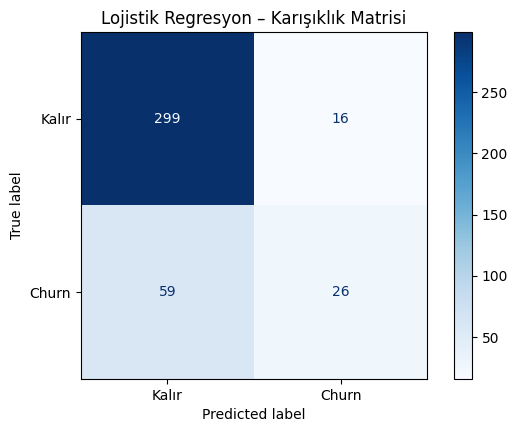

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = lojistik.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=["Kalır", "Churn"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Kalır", "Churn"], cmap="Blues")
plt.title("Lojistik Regresyon – Karışıklık Matrisi")
plt.show()

> 💼 **İş yorumu:** Churn problemi için genellikle **recall** daha önemlidir; çünkü gidecek bir müşteriyi kaçırmanın (FN) maliyeti, gitmeyecek bir müşteriye gereksiz indirim vermekten (FP) çoğu zaman daha yüksektir. Hangi metriğin önemli olduğuna **iş problemi** karar verir.

### Olasılık tahmini, eşik değeri ve ROC eğrisi

İlk 5 müşterinin churn olasılığı: [0.024 0.335 0.174 0.156 0.358]
ROC-AUC: 0.784
Eşik 0.5: precision = 0.62, recall = 0.31
Eşik 0.4: precision = 0.56, recall = 0.45
Eşik 0.3: precision = 0.45, recall = 0.54
Eşik 0.2: precision = 0.40, recall = 0.76


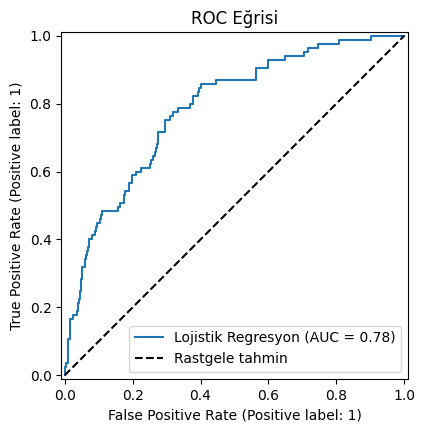

In [12]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay, recall_score, precision_score

olasilik = lojistik.predict_proba(X_test)[:, 1]   # churn olasılığı
print("İlk 5 müşterinin churn olasılığı:", olasilik[:5].round(3))
print("ROC-AUC:", round(roc_auc_score(y_test, olasilik), 3))

# Eşiği değiştirerek kesinlik/duyarlılık dengesini ayarlayabiliriz
for esik in [0.5, 0.4, 0.3, 0.2]:
    tahmin = (olasilik >= esik).astype(int)
    print(f"Eşik {esik}: precision = {precision_score(y_test, tahmin):.2f}, recall = {recall_score(y_test, tahmin):.2f}")

RocCurveDisplay.from_predictions(y_test, olasilik, name="Lojistik Regresyon")
plt.plot([0, 1], [0, 1], "k--", label="Rastgele tahmin")
plt.legend()
plt.title("ROC Eğrisi")
plt.show()

### Katsayıları yorumlama
Lojistik regresyonun katsayıları, her değişkenin churn olasılığını **artırıcı (+)** mı **azaltıcı (−)** mı etkilediğini gösterir.

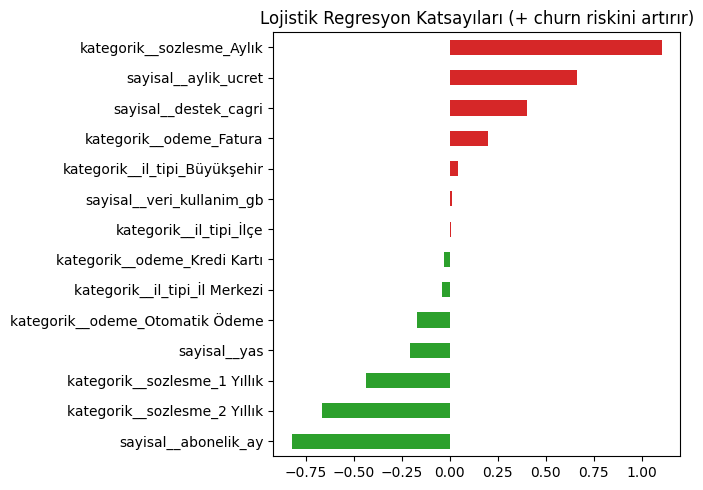

In [13]:
isimler = lojistik.named_steps["on_isleme"].get_feature_names_out()
katsayilar = pd.Series(lojistik.named_steps["model"].coef_[0], index=isimler).sort_values()

katsayilar.plot(kind="barh", color=np.where(katsayilar > 0, "tab:red", "tab:green"), figsize=(7, 5))
plt.title("Lojistik Regresyon Katsayıları (+ churn riskini artırır)")
plt.tight_layout()
plt.show()

### ✍️ Alıştırma 1
1. Pipeline'daki modeli `LogisticRegression(max_iter=1000, class_weight="balanced")` ile değiştirerek yeni bir pipeline kurun ve eğitin.
2. Test verisi üzerinde `classification_report` çıktısını alın.
3. Churn sınıfı için recall değeri nasıl değişti? `class_weight="balanced"` sizce ne işe yarıyor? (Cevabınızı yorum satırı olarak yazın.)

In [14]:
# Kodunuzu buraya yazın

## 6. Farklı Algoritmaları Karşılaştırma
Ortak API sayesinde sadece model satırını değiştirerek farklı algoritmaları deneyebiliriz.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

modeller = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000),
    "Karar Ağacı": DecisionTreeClassifier(random_state=42),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Rastgele Orman": RandomForestClassifier(n_estimators=200, random_state=42),
}

sonuclar = []
for ad, mdl in modeller.items():
    pipe = Pipeline([("on_isleme", on_isleme), ("model", mdl)]).fit(X_train, y_train)
    sonuclar.append({
        "Model": ad,
        "Eğitim doğruluğu": pipe.score(X_train, y_train),
        "Test doğruluğu": pipe.score(X_test, y_test),
        "Test F1": f1_score(y_test, pipe.predict(X_test)),
        "Test ROC-AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]),
    })

pd.DataFrame(sonuclar).set_index("Model").round(3)

,Eğitim doğruluğu,Test doğruluğu,Test F1,Test ROC-AUC
Model,,,,
Lojistik Regresyon,0.811,0.812,0.409,0.784
Karar Ağacı,1.000,0.732,0.422,0.633
KNN (k=15),0.813,0.798,0.296,0.758
Rastgele Orman,1.000,0.800,0.344,0.778


> 🔎 **Aşırı öğrenme (overfitting):** Sınırsız derinlikteki karar ağacının **eğitim** doğruluğu ~1.00 iken test doğruluğu belirgin şekilde düşük. Model veriyi genellemek yerine **ezberlemiş**. Bunu `max_depth` gibi parametrelerle sınırlayarak çözeriz.

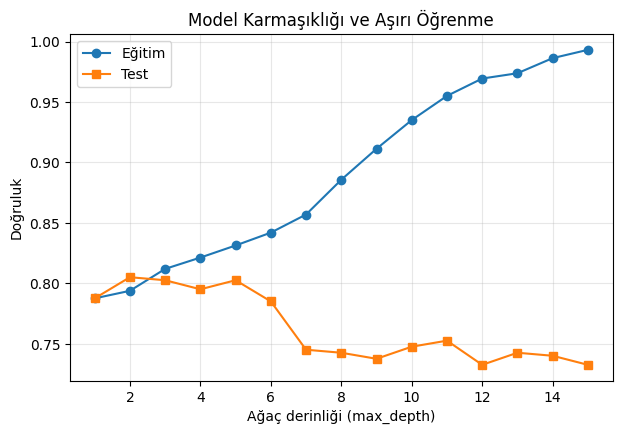

In [16]:
from sklearn.tree import plot_tree

derinlikler = range(1, 16)
egitim_skor, test_skor = [], []
for d in derinlikler:
    p = Pipeline([("on_isleme", on_isleme), ("model", DecisionTreeClassifier(max_depth=d, random_state=42))])
    p.fit(X_train, y_train)
    egitim_skor.append(p.score(X_train, y_train))
    test_skor.append(p.score(X_test, y_test))

plt.plot(derinlikler, egitim_skor, marker="o", label="Eğitim")
plt.plot(derinlikler, test_skor, marker="s", label="Test")
plt.xlabel("Ağaç derinliği (max_depth)")
plt.ylabel("Doğruluk")
plt.title("Model Karmaşıklığı ve Aşırı Öğrenme")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

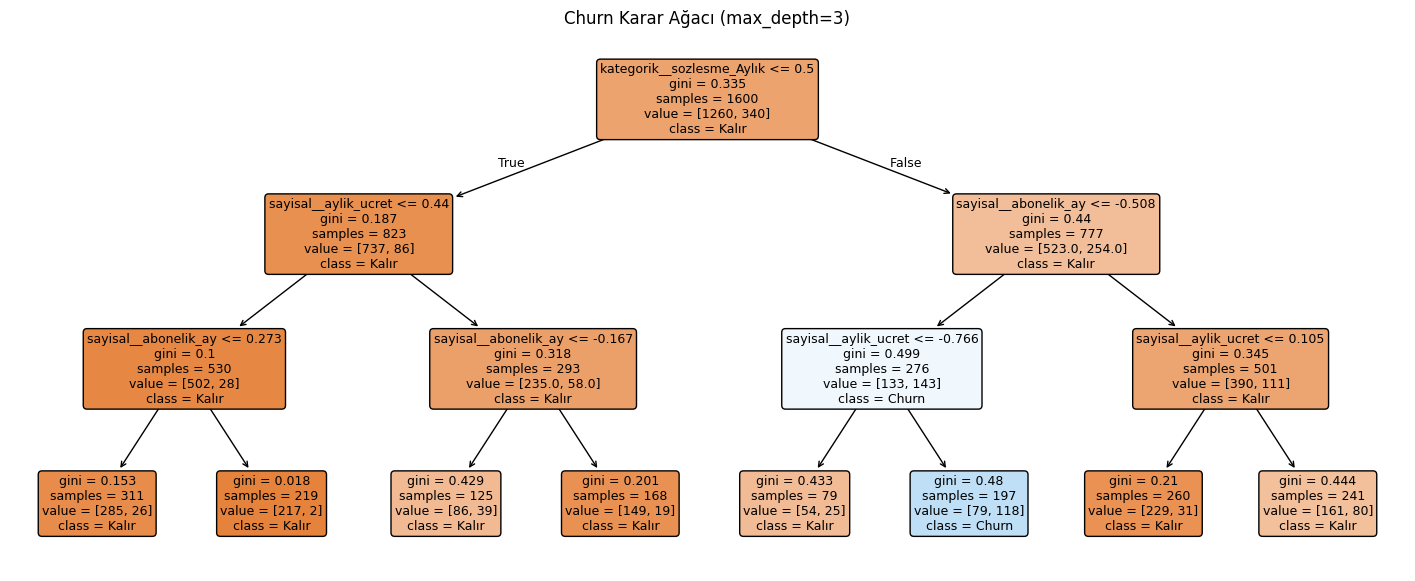

In [17]:
# Sığ bir ağacı görselleştirme: karar ağaçlarının en büyük avantajı yorumlanabilirliktir
kucuk_agac = Pipeline([("on_isleme", on_isleme), ("model", DecisionTreeClassifier(max_depth=3, random_state=42))])
kucuk_agac.fit(X_train, y_train)

plt.figure(figsize=(18, 7))
plot_tree(kucuk_agac.named_steps["model"], feature_names=list(isimler), class_names=["Kalır", "Churn"],
          filled=True, rounded=True, fontsize=9)
plt.title("Churn Karar Ağacı (max_depth=3)")
plt.show()

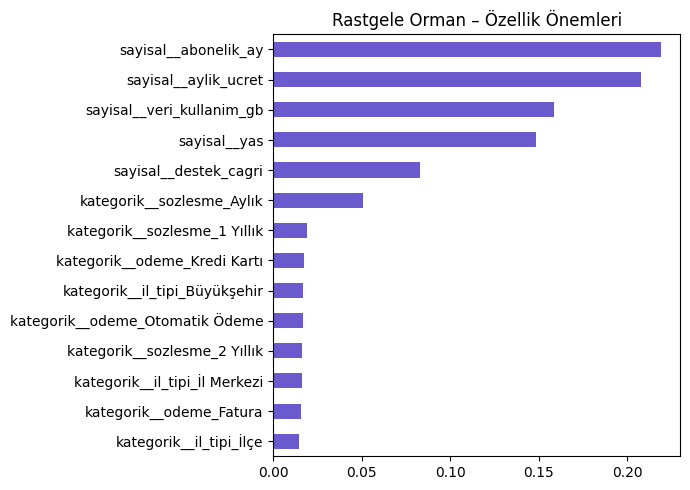

In [18]:
# Rastgele ormandan özellik önem düzeyleri
orman = Pipeline([("on_isleme", on_isleme), ("model", RandomForestClassifier(n_estimators=200, random_state=42))])
orman.fit(X_train, y_train)
onem = pd.Series(orman.named_steps["model"].feature_importances_, index=isimler).sort_values()
onem.plot(kind="barh", figsize=(7, 5), color="slateblue", title="Rastgele Orman – Özellik Önemleri")
plt.tight_layout()
plt.show()

## 7. Çapraz Doğrulama (Cross-Validation) ⭐
Tek bir eğitim/test bölmesinin sonucu **şansa** bağlı olabilir. K-katlı çapraz doğrulamada eğitim verisi K parçaya bölünür; model K kez eğitilir ve her seferinde farklı bir parça doğrulama için kullanılır. Sonuç: daha **güvenilir** bir performans tahmini.

In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skorlar = cross_val_score(lojistik, X_train, y_train, cv=cv, scoring="roc_auc")

print("Her katın ROC-AUC değeri:", skorlar.round(3))
print(f"Ortalama: {skorlar.mean():.3f} ± {skorlar.std():.3f}")

Her katın ROC-AUC değeri: [0.815 0.787 0.856 0.812 0.79 ]
Ortalama: 0.812 ± 0.025


## 8. Hiperparametre Ayarlama: `GridSearchCV`
**Parametre:** modelin veriden öğrendiği değerler (ör. katsayılar).
**Hiperparametre:** bizim önceden belirlediğimiz ayarlar (ör. `max_depth`, `n_neighbors`).
`GridSearchCV`, verilen tüm kombinasyonları çapraz doğrulama ile dener ve en iyisini seçer.

In [20]:
from sklearn.model_selection import GridSearchCV

agac_pipe = Pipeline([("on_isleme", on_isleme), ("model", DecisionTreeClassifier(random_state=42))])

param_izgarasi = {
    "model__max_depth": [3, 4, 5, 6, 8],          # pipeline adımı + __ + parametre adı
    "model__min_samples_leaf": [1, 10, 30],
}

arama = GridSearchCV(agac_pipe, param_izgarasi, cv=cv, scoring="roc_auc", n_jobs=-1)
arama.fit(X_train, y_train)

print("En iyi parametreler:", arama.best_params_)
print("En iyi CV ROC-AUC  :", round(arama.best_score_, 3))
print("Test ROC-AUC       :", round(roc_auc_score(y_test, arama.predict_proba(X_test)[:, 1]), 3))

En iyi parametreler: {'model__max_depth': 4, 'model__min_samples_leaf': 30}
En iyi CV ROC-AUC  : 0.774
Test ROC-AUC       : 0.745


### Yeni müşteriler için tahmin
Eğitilmiş pipeline'a ham veriyi verebiliriz; ölçekleme ve kodlama otomatik yapılır.

In [21]:
yeni_musteriler = pd.DataFrame({
    "yas": [23, 55],
    "abonelik_ay": [3, 60],
    "aylik_ucret": [780, 320],
    "destek_cagri": [5, 0],
    "veri_kullanim_gb": [40, 8],
    "sozlesme": ["Aylık", "2 Yıllık"],
    "odeme": ["Fatura", "Otomatik Ödeme"],
    "il_tipi": ["Büyükşehir", "İlçe"],
})
yeni_musteriler["churn_olasiligi"] = arama.predict_proba(yeni_musteriler)[:, 1].round(3)
yeni_musteriler

,yas,abonelik_ay,aylik_ucret,destek_cagri,veri_kullanim_gb,sozlesme,odeme,il_tipi,churn_olasiligi
0,23,3,780,5,40,Aylık,Fatura,Büyükşehir,0.725
1,55,60,320,0,8,2 Yıllık,Otomatik Ödeme,İlçe,0.025


### ✍️ Alıştırma 2
1. `KNeighborsClassifier` kullanan bir pipeline kurun.
2. `GridSearchCV` ile `n_neighbors` için `[3, 5, 11, 21, 31, 51]` ve `weights` için `["uniform", "distance"]` değerlerini 5 katlı çapraz doğrulama ile deneyin (`scoring="f1"`).
3. En iyi parametreleri ve test verisindeki F1 skorunu yazdırın.

In [22]:
# Kodunuzu buraya yazın

## 9. Regresyon: Konut Fiyatı Tahmini
Hedef değişken **sayısal** olduğunda regresyon kullanılır. Metrikler farklıdır:
- **MAE:** Ortalama mutlak hata (hedefle aynı birimde, yorumlaması kolay)
- **RMSE:** Kök ortalama kare hata (büyük hataları daha çok cezalandırır)
- **R²:** Modelin açıkladığı varyans oranı (1'e ne kadar yakınsa o kadar iyi)

In [23]:
rng_k = np.random.default_rng(7)
m = 800
konut = pd.DataFrame({
    "metrekare": rng_k.uniform(55, 250, m).round(),
    "oda": rng_k.integers(1, 6, m),
    "bina_yasi": rng_k.integers(0, 40, m),
    "merkeze_km": rng_k.uniform(0.5, 15, m).round(1),
    "ilce": rng_k.choice(["Merkez", "Kelkit", "Şiran", "Torul"], m, p=[0.5, 0.2, 0.15, 0.15]),
})
konut["fiyat"] = (
    25000 * konut["metrekare"]
    + 150000 * konut["oda"]
    - 30000 * konut["bina_yasi"]
    - 60000 * konut["merkeze_km"]
    + konut["ilce"].map({"Merkez": 400000, "Kelkit": 100000, "Şiran": 0, "Torul": -50000})
    + rng_k.normal(0, 250000, m)
).round(-3)
konut.head()

,metrekare,oda,bina_yasi,merkeze_km,ilce,fiyat
0,177.0,4,29,11.5,Merkez,3676000.0
1,230.0,5,3,7.9,Merkez,6302000.0
2,206.0,4,5,2.8,Kelkit,5753000.0
3,99.0,1,28,3.6,Torul,1458000.0
4,114.0,5,1,6.0,Merkez,3263000.0


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

Xk = konut.drop(columns="fiyat")
yk = konut["fiyat"]
Xk_train, Xk_test, yk_train, yk_test = train_test_split(Xk, yk, test_size=0.2, random_state=42)

konut_on_isleme = ColumnTransformer([
    ("sayisal", StandardScaler(), ["metrekare", "oda", "bina_yasi", "merkeze_km"]),
    ("kategorik", OneHotEncoder(handle_unknown="ignore"), ["ilce"]),
])

reg_modeller = {
    "Doğrusal Regresyon": LinearRegression(),
    "Rastgele Orman": RandomForestRegressor(n_estimators=200, random_state=42),
}

for ad, mdl in reg_modeller.items():
    pipe = Pipeline([("on_isleme", konut_on_isleme), ("model", mdl)]).fit(Xk_train, yk_train)
    tahmin = pipe.predict(Xk_test)
    print(f"{ad:20s} MAE = {mean_absolute_error(yk_test, tahmin):>10,.0f} TL | "
          f"RMSE = {np.sqrt(mean_squared_error(yk_test, tahmin)):>10,.0f} TL | R² = {r2_score(yk_test, tahmin):.3f}")

Doğrusal Regresyon   MAE =    202,078 TL | RMSE =    246,353 TL | R² = 0.972
Rastgele Orman       MAE =    268,536 TL | RMSE =    340,520 TL | R² = 0.946


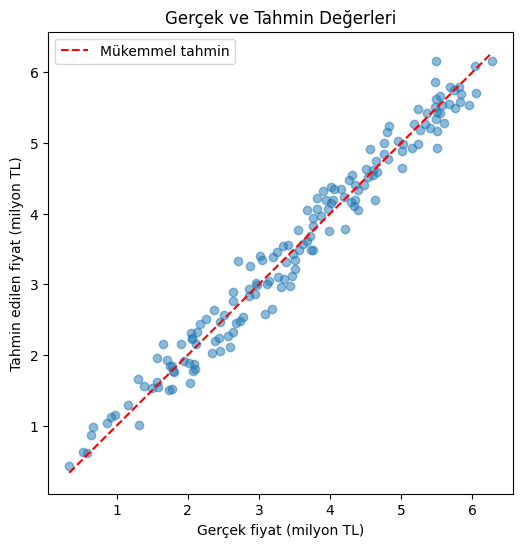

In [25]:
dogrusal = Pipeline([("on_isleme", konut_on_isleme), ("model", LinearRegression())]).fit(Xk_train, yk_train)
tahmin = dogrusal.predict(Xk_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yk_test / 1e6, tahmin / 1e6, alpha=0.5)
sinir = [yk_test.min() / 1e6, yk_test.max() / 1e6]
ax.plot(sinir, sinir, "r--", label="Mükemmel tahmin")
ax.set_xlabel("Gerçek fiyat (milyon TL)")
ax.set_ylabel("Tahmin edilen fiyat (milyon TL)")
ax.set_title("Gerçek ve Tahmin Değerleri")
ax.legend()
plt.show()

### ✍️ Alıştırma 3
1. Doğrusal regresyon modelinin katsayılarını özellik isimleriyle birlikte bir `Series` olarak gösterin. (İpucu: `dogrusal.named_steps[...]`)
2. Merkez ilçede, 120 m², 3 odalı, 5 yıllık, merkeze 2 km uzaklıktaki bir dairenin fiyatını tahmin edin.
3. `cross_val_score` ile doğrusal regresyon pipeline'ının 5 katlı R² ortalamasını hesaplayın.

In [26]:
# Kodunuzu buraya yazın

## 10. Kümeleme (Denetimsiz Öğrenme): Müşteri Segmentasyonu
Hedef değişken **yoktur**. Amaç, birbirine benzeyen gözlemleri gruplamaktır. **K-Means** en yaygın algoritmadır ve mesafe tabanlı olduğu için **ölçeklendirme şarttır**.

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng_s = np.random.default_rng(1)
merkezler = [(25, 4, 800), (45, 15, 4500), (35, 30, 2000), (60, 6, 9000)]
segment_df = pd.DataFrame(np.vstack([
    np.column_stack([rng_s.normal(a, 4, 100), rng_s.normal(f, 3, 100), rng_s.normal(h, h * 0.15, 100)])
    for a, f, h in merkezler
]), columns=["yas", "yillik_alisveris", "yillik_harcama"]).clip(lower=1).round(0)

segment_df.describe().round(0)

,yas,yillik_alisveris,yillik_harcama
count,400.0,400.0,400.0
mean,41.0,14.0,4078.0
std,14.0,11.0,3272.0
min,14.0,1.0,505.0
25%,29.0,5.0,1206.0
50%,40.0,11.0,2663.0
75%,51.0,22.0,5988.0
max,69.0,36.0,12381.0


### Küme sayısını seçme: Dirsek yöntemi ve Silhouette skoru
- **Dirsek (elbow):** Küme içi kareler toplamının (inertia) azalma hızının belirgin şekilde yavaşladığı nokta
- **Silhouette:** -1 ile 1 arası; yüksek değer kümelerin iyi ayrıştığını gösterir

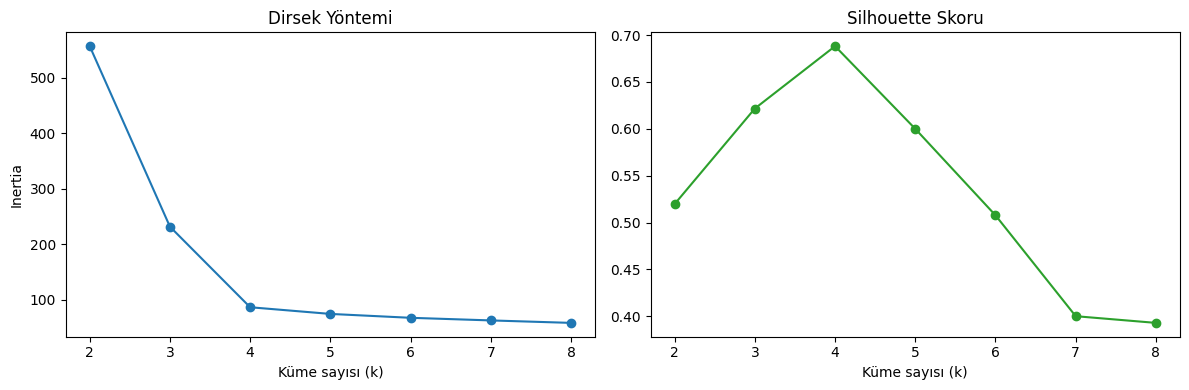

In [28]:
X_seg = StandardScaler().fit_transform(segment_df)

k_degerleri = range(2, 9)
inertia, silhouette = [], []
for k in k_degerleri:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_seg)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_seg, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_degerleri, inertia, marker="o")
axes[0].set_title("Dirsek Yöntemi")
axes[0].set_xlabel("Küme sayısı (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_degerleri, silhouette, marker="o", color="tab:green")
axes[1].set_title("Silhouette Skoru")
axes[1].set_xlabel("Küme sayısı (k)")
plt.tight_layout()
plt.show()

In [29]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
segment_df["kume"] = kmeans.fit_predict(X_seg)

# Kümelerin profilini çıkarmak: kümelemenin asıl iş değeri buradadır
profil = segment_df.groupby("kume").agg(
    musteri_sayisi=("yas", "size"),
    ort_yas=("yas", "mean"),
    ort_alisveris=("yillik_alisveris", "mean"),
    ort_harcama=("yillik_harcama", "mean"),
).round(0)
profil

,musteri_sayisi,ort_yas,ort_alisveris,ort_harcama
kume,,,,
0,101,45.0,15.0,4411.0
1,99,35.0,30.0,2030.0
2,100,25.0,4.0,781.0
3,100,60.0,6.0,9069.0


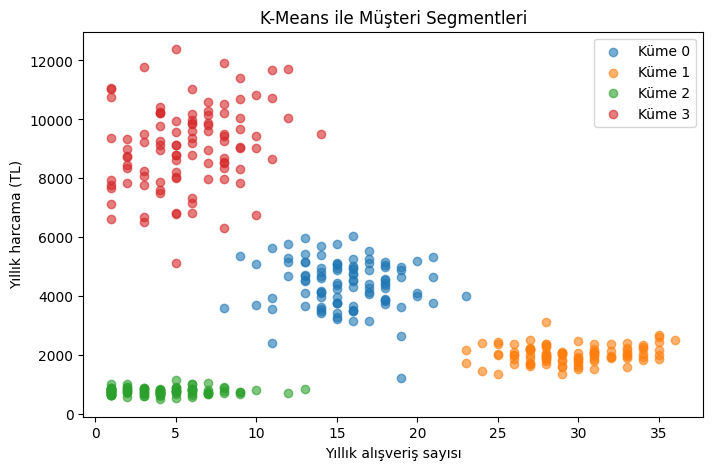

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
for k, grup in segment_df.groupby("kume"):
    ax.scatter(grup["yillik_alisveris"], grup["yillik_harcama"], label=f"Küme {k}", alpha=0.6)
ax.set_xlabel("Yıllık alışveriş sayısı")
ax.set_ylabel("Yıllık harcama (TL)")
ax.set_title("K-Means ile Müşteri Segmentleri")
ax.legend()
plt.show()

> 💼 **İş yorumu:** Profil tablosuna bakarak kümelere anlamlı isimler verin. Örneğin "sık ama az harcayan genç müşteriler", "seyrek gelen ama yüksek harcayan olgun müşteriler" gibi. Her segment için farklı pazarlama stratejisi geliştirilebilir.

## 11. Boyut İndirgeme: PCA (Kısa Bakış)
Çok sayıda değişkeni, bilginin büyük kısmını koruyarak daha az sayıda **temel bileşene** indirger. Görselleştirme ve gürültü azaltmada kullanılır.

Açıklanan varyans oranları: [0.157 0.153]


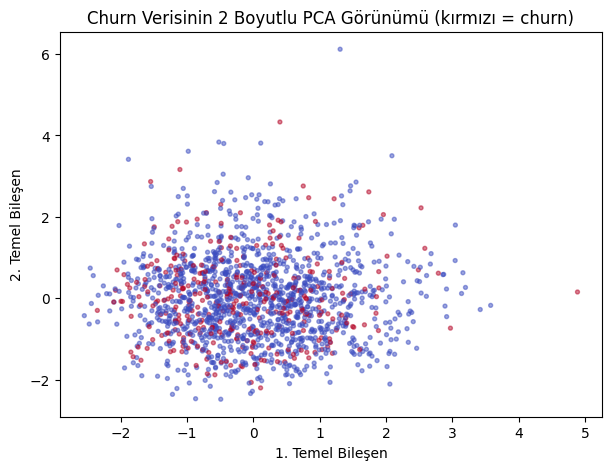

In [31]:
from sklearn.decomposition import PCA

churn_X = Pipeline([("on_isleme", on_isleme)]).fit_transform(X_train)
pca = PCA(n_components=2)
bilesenler = pca.fit_transform(churn_X)

print("Açıklanan varyans oranları:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(7, 5))
plt.scatter(bilesenler[:, 0], bilesenler[:, 1], c=y_train, cmap="coolwarm", s=8, alpha=0.5)
plt.xlabel("1. Temel Bileşen")
plt.ylabel("2. Temel Bileşen")
plt.title("Churn Verisinin 2 Boyutlu PCA Görünümü (kırmızı = churn)")
plt.show()

## 12. Modeli Kaydetme ve Yükleme
Eğitilen model, daha sonra bir uygulamada kullanılmak üzere dosyaya kaydedilebilir.

In [32]:
import joblib

joblib.dump(arama.best_estimator_, "churn_modeli.joblib")
yuklenen = joblib.load("churn_modeli.joblib")
print("Yüklenen modelin test doğruluğu:", round(yuklenen.score(X_test, y_test), 3))

Yüklenen modelin test doğruluğu: 0.802


### ✍️ Alıştırma 4 (Kapsamlı Proje): Kredi Onayı
Bir banka, kredi başvurularının geri ödenip ödenmeyeceğini (`temerrut`: 1 = ödemedi) tahmin etmek istiyor. Aşağıdaki hücre veriyi üretir. Görevleriniz:
1. Veriyi `stratify` kullanarak %75 eğitim, %25 test olarak bölün.
2. Sayısal sütunları ölçekleyen, kategorik sütunları one-hot kodlayan bir `ColumnTransformer` kurun.
3. Lojistik regresyon ve rastgele orman modellerini 5 katlı çapraz doğrulama ile (`scoring="roc_auc"`) karşılaştırın.
4. Daha iyi olan modeli eğitim verisiyle eğitip test setinde karışıklık matrisini ve `classification_report`'u gösterin.
5. Bankacılık açısından hangi hata türü (FP mi, FN mi) daha maliyetlidir? Yorum satırı olarak yazın.

In [33]:
rng_b = np.random.default_rng(99)
nb = 1500
kredi = pd.DataFrame({
    "yas": rng_b.integers(21, 70, nb),
    "aylik_gelir": rng_b.lognormal(10.2, 0.45, nb).round(-1),
    "kredi_tutari": rng_b.uniform(20000, 500000, nb).round(-3),
    "vade_ay": rng_b.choice([12, 24, 36, 48, 60], nb),
    "mevcut_kredi_sayisi": rng_b.poisson(1.2, nb),
    "is_tipi": rng_b.choice(["Kamu", "Özel Sektör", "Serbest Meslek", "Emekli"], nb, p=[0.25, 0.45, 0.2, 0.1]),
    "ev_durumu": rng_b.choice(["Ev Sahibi", "Kiracı", "Aile Yanı"], nb, p=[0.4, 0.45, 0.15]),
})
oran = kredi["kredi_tutari"] / (kredi["aylik_gelir"] * kredi["vade_ay"])
z = (-3.6 + 6 * oran + 0.35 * kredi["mevcut_kredi_sayisi"] - 0.02 * (kredi["yas"] - 40)
     + kredi["is_tipi"].map({"Kamu": -0.7, "Özel Sektör": 0, "Serbest Meslek": 0.5, "Emekli": -0.3})
     + kredi["ev_durumu"].map({"Ev Sahibi": -0.5, "Kiracı": 0.2, "Aile Yanı": 0.1}))
kredi["temerrut"] = (rng_b.random(nb) < 1 / (1 + np.exp(-z))).astype(int)

print("Temerrüt oranı:", kredi["temerrut"].mean().round(3))
kredi.head()

Temerrüt oranı: 0.289


,yas,aylik_gelir,kredi_tutari,vade_ay,mevcut_kredi_sayisi,is_tipi,ev_durumu,temerrut
0,67,27410.0,301000.0,60,3,Özel Sektör,Kiracı,1
1,45,26840.0,226000.0,60,0,Serbest Meslek,Ev Sahibi,0
2,58,17600.0,134000.0,12,2,Kamu,Ev Sahibi,1
3,48,18430.0,275000.0,48,1,Kamu,Ev Sahibi,0
4,29,35770.0,72000.0,12,0,Özel Sektör,Kiracı,0


In [34]:
# Kodunuzu buraya yazın

---
## 📌 Özet
| Adım | scikit-learn araçları |
|---|---|
| Bölme | `train_test_split(stratify=...)` |
| Ön işleme | `StandardScaler`, `MinMaxScaler`, `OneHotEncoder`, `ColumnTransformer` |
| Zincirleme | `Pipeline` (veri sızıntısını önler) |
| Sınıflandırma | `LogisticRegression`, `DecisionTreeClassifier`, `KNeighborsClassifier`, `RandomForestClassifier` |
| Regresyon | `LinearRegression`, `RandomForestRegressor` |
| Kümeleme / boyut indirgeme | `KMeans`, `PCA` |
| Değerlendirme | `confusion_matrix`, `classification_report`, `roc_auc_score`, `MAE`, `RMSE`, `R²`, `silhouette_score` |
| Model seçimi | `cross_val_score`, `StratifiedKFold`, `GridSearchCV` |

### Akılda tutulacak 5 kural
1. Test verisine modelleme bitene kadar **dokunmayın**; dönüştürücüleri sadece eğitim verisiyle `fit` edin.
2. Dengesiz veride doğruluğa güvenmeyin; **precision, recall, F1, ROC-AUC**'a bakın.
3. Her zaman basit bir **referans (baseline)** modelle karşılaştırın.
4. Eğitim ve test skorları arasındaki büyük fark **aşırı öğrenmeye** işarettir.
5. Metriği ve eşiği **iş problemi** belirler; model sonuçlarını iş diliyle yorumlayın.

---
## ✅ Çözümler

### Çözüm 1

In [35]:
dengeli = Pipeline([
    ("on_isleme", on_isleme),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
]).fit(X_train, y_train)

print(classification_report(y_test, dengeli.predict(X_test), target_names=["Kalır", "Churn"]))
# class_weight="balanced", azınlık sınıfındaki (churn) hatalara daha yüksek ceza verir.
# Böylece model churn edenleri daha çok yakalar: recall artar, buna karşılık precision bir miktar düşer.

              precision    recall  f1-score   support

       Kalır       0.92      0.70      0.79       315
       Churn       0.40      0.76      0.53        85

    accuracy                           0.71       400
   macro avg       0.66      0.73      0.66       400
weighted avg       0.81      0.71      0.73       400



### Çözüm 2

In [36]:
knn_pipe = Pipeline([("on_isleme", on_isleme), ("model", KNeighborsClassifier())])
knn_arama = GridSearchCV(
    knn_pipe,
    {"model__n_neighbors": [3, 5, 11, 21, 31, 51], "model__weights": ["uniform", "distance"]},
    cv=5, scoring="f1", n_jobs=-1,
).fit(X_train, y_train)

print("En iyi parametreler:", knn_arama.best_params_)
print("Test F1:", round(f1_score(y_test, knn_arama.predict(X_test)), 3))

En iyi parametreler: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Test F1: 0.351


### Çözüm 3

In [37]:
katsayi = pd.Series(
    dogrusal.named_steps["model"].coef_,
    index=dogrusal.named_steps["on_isleme"].get_feature_names_out(),
).round(0)
print(katsayi)

daire = pd.DataFrame({"metrekare": [120], "oda": [3], "bina_yasi": [5], "merkeze_km": [2.0], "ilce": ["Merkez"]})
print(f"\nTahmini fiyat: {dogrusal.predict(daire)[0]:,.0f} TL")

r2 = cross_val_score(Pipeline([("on_isleme", konut_on_isleme), ("model", LinearRegression())]),
                     Xk, yk, cv=5, scoring="r2")
print("5 katlı R² ortalaması:", r2.mean().round(3))

sayisal__metrekare        1375099.0
sayisal__oda               217953.0
sayisal__bina_yasi        -328485.0
sayisal__merkeze_km       -248702.0
kategorik__ilce_Kelkit     -23415.0
kategorik__ilce_Merkez     280503.0
kategorik__ilce_Torul     -154927.0
kategorik__ilce_Şiran     -102160.0
dtype: float64

Tahmini fiyat: 3,554,443 TL
5 katlı R² ortalaması: 0.973


### Çözüm 4

Lojistik Regresyon: CV ROC-AUC = 0.875 ± 0.024
Rastgele Orman: CV ROC-AUC = 0.867 ± 0.029

Seçilen model: Lojistik Regresyon
              precision    recall  f1-score   support

       Ödedi       0.83      0.88      0.85       267
    Temerrüt       0.65      0.55      0.59       108

    accuracy                           0.78       375
   macro avg       0.74      0.71      0.72       375
weighted avg       0.78      0.78      0.78       375



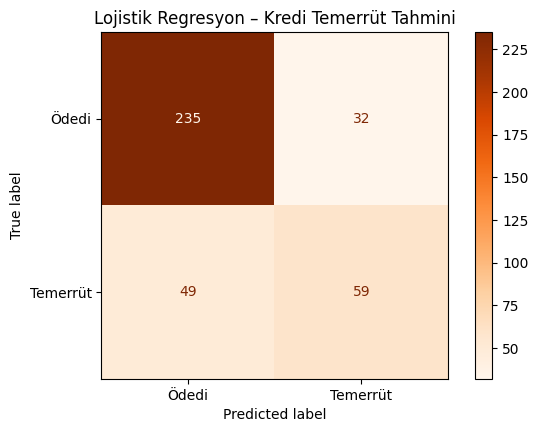

In [38]:
Xb = kredi.drop(columns="temerrut")
yb = kredi["temerrut"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.25, random_state=42, stratify=yb)

kredi_on_isleme = ColumnTransformer([
    ("sayisal", StandardScaler(), ["yas", "aylik_gelir", "kredi_tutari", "vade_ay", "mevcut_kredi_sayisi"]),
    ("kategorik", OneHotEncoder(handle_unknown="ignore"), ["is_tipi", "ev_durumu"]),
])

adaylar = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000),
    "Rastgele Orman": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_sonuc = {}
for ad, mdl in adaylar.items():
    s = cross_val_score(Pipeline([("on_isleme", kredi_on_isleme), ("model", mdl)]), Xb_train, yb_train, cv=cv5, scoring="roc_auc")
    cv_sonuc[ad] = s.mean()
    print(f"{ad}: CV ROC-AUC = {s.mean():.3f} ± {s.std():.3f}")

en_iyi_ad = max(cv_sonuc, key=cv_sonuc.get)
print("\nSeçilen model:", en_iyi_ad)
final = Pipeline([("on_isleme", kredi_on_isleme), ("model", adaylar[en_iyi_ad])]).fit(Xb_train, yb_train)
yb_pred = final.predict(Xb_test)
print(classification_report(yb_test, yb_pred, target_names=["Ödedi", "Temerrüt"]))
ConfusionMatrixDisplay.from_predictions(yb_test, yb_pred, display_labels=["Ödedi", "Temerrüt"], cmap="Oranges")
plt.title(f"{en_iyi_ad} – Kredi Temerrüt Tahmini")
plt.show()

# Bankacılıkta FN (temerrüde düşecek kişiye kredi vermek) genellikle daha maliyetlidir:
# kredinin anaparası kaybedilebilir. FP ise (ödeyecek kişiyi reddetmek) yalnızca faiz gelirini kaybettirir.
# Bu nedenle eşik değeri düşürülerek recall artırılabilir veya class_weight kullanılabilir.